# Adaptive Dynamic RFM — Customer Behavior Analysis & Prediction

**Đề tài:** Phân tích và dự báo hành vi khách hàng sử dụng mô hình Dynamic RFM.

Notebook triển khai:
- Cleaning dữ liệu giao dịch Online Retail II.
- Monthly snapshots và nhãn **mua hàng trong tháng kế tiếp**.
- Temporal Train / Validation / Test split.
- Baseline Lifetime/Static RFM và Fixed Rolling RFM.
- Proposed method: Adaptive Rolling Window + Temporal Features.
- So sánh Logistic Regression, Random Forest, XGBoost (nếu cài đặt).
- Chỉ dùng Validation để lựa chọn window/model; Test chỉ dùng đánh giá cuối cùng.

> Lưu ý: Đây là notebook nghiên cứu thực nghiệm. Các kết quả sẽ được tính khi chạy trên dataset thực tế; không có metric giả lập được ghi sẵn.


## 1. Import libraries & configuration

In [1]:
import warnings, os, glob
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report
)

RANDOM_STATE = 42
DATA_PATH = None  # Set path, e.g. r"/content/online_retail_ii.xlsx"
WINDOWS = [30, 60, 90, 120, 180]
SNAPSHOT_START = "2010-01"
SNAPSHOT_END = "2011-10"  # October snapshot predicts November (complete month)
TRAIN_END = "2010-12"
VALID_START, VALID_END = "2011-01", "2011-06"
TEST_START, TEST_END = "2011-07", "2011-10"

pd.set_option("display.max_columns", 100)


## 2. Load Online Retail II
Upload the Excel file or set `DATA_PATH`. The loader reads both sheets when available.

In [2]:
def find_dataset():
    if DATA_PATH and os.path.exists(DATA_PATH):
        return DATA_PATH
    candidates = (
        glob.glob("**/*online*retail*ii*.xlsx", recursive=True) +
        glob.glob("**/*retail*ii*.xlsx", recursive=True) +
        glob.glob("**/*.xlsx", recursive=True)
    )
    return candidates[0] if candidates else None

path = find_dataset()
if path is None:
    try:
        from google.colab import files
        uploaded = files.upload()
        path = next(iter(uploaded.keys()))
    except Exception:
        raise FileNotFoundError("Set DATA_PATH to the Online Retail II Excel file.")

print("Dataset:", path)

xls = pd.ExcelFile(path)
frames = []
for sheet in xls.sheet_names:
    tmp = pd.read_excel(path, sheet_name=sheet)
    frames.append(tmp)
df_raw = pd.concat(frames, ignore_index=True)
print("Raw shape:", df_raw.shape)
display(df_raw.head())


Saving Online Retail.xlsx to Online Retail.xlsx
Dataset: Online Retail.xlsx
Raw shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 3. Data Understanding

In [3]:
display(df_raw.info())
display(df_raw.isna().sum().sort_values(ascending=False))
display(df_raw.describe(include="all").T)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


None

,0
CustomerID,135080
Description,1454
StockCode,0
InvoiceNo,0
Quantity,0
InvoiceDate,0
UnitPrice,0
Country,0


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Basic Data Cleaning
Cleaning rules are based on record validity, not statistics learned from the entire dataset.

In [5]:
import pandas as pd
import numpy as np

# ============================================================
# 1. COPY RAW DATA
# ============================================================

df = df_raw.copy()

# Normalize column names
df.columns = [str(c).strip() for c in df.columns]

# ============================================================
# 2. NORMALIZE COLUMN NAMES
# Supports Online Retail I and other compatible datasets
# ============================================================

rename_map = {
    "InvoiceNo": "Invoice",
    "Invoice": "Invoice",

    "StockCode": "StockCode",

    "Description": "Description",

    "Quantity": "Quantity",

    "InvoiceDate": "InvoiceDate",

    "UnitPrice": "UnitPrice",
    "Price": "UnitPrice",

    "CustomerID": "CustomerID",
    "Customer ID": "CustomerID",

    "Country": "Country"
}

df = df.rename(columns=rename_map)

# ============================================================
# 3. VALIDATE REQUIRED COLUMNS
# ============================================================

required = [
    "Invoice",
    "Quantity",
    "InvoiceDate",
    "UnitPrice",
    "CustomerID"
]

missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(
        f"Missing required columns: {missing}\n"
        f"Available columns: {df.columns.tolist()}"
    )

print("Column validation passed.")

# ============================================================
# 4. DATA TYPE CONVERSION
# ============================================================

df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    errors="coerce"
)

df["CustomerID"] = pd.to_numeric(
    df["CustomerID"],
    errors="coerce"
)

df["Quantity"] = pd.to_numeric(
    df["Quantity"],
    errors="coerce"
)

df["UnitPrice"] = pd.to_numeric(
    df["UnitPrice"],
    errors="coerce"
)

# ============================================================
# 5. REMOVE MISSING / INVALID VALUES
# ============================================================

df = df.dropna(
    subset=[
        "Invoice",
        "InvoiceDate",
        "CustomerID",
        "Quantity",
        "UnitPrice"
    ]
)

# CustomerID must be integer
df["CustomerID"] = df["CustomerID"].astype("int64")

# Normalize Invoice ID
df["Invoice"] = (
    df["Invoice"]
    .astype(str)
    .str.strip()
)

# ============================================================
# 6. REMOVE CANCELLED INVOICES
# ============================================================

df = df[
    ~df["Invoice"]
    .str.upper()
    .str.startswith("C", na=False)
]

# ============================================================
# 7. REMOVE INVALID TRANSACTIONS
# ============================================================

df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
]

# ============================================================
# 8. REMOVE EXACT DUPLICATES
# ============================================================

df = df.drop_duplicates()

# ============================================================
# 9. FEATURE ENGINEERING
# ============================================================

df["TotalAmount"] = (
    df["Quantity"] *
    df["UnitPrice"]
)

# ============================================================
# 10. SORT TRANSACTIONS BY TIME
# ============================================================

df = (
    df.sort_values("InvoiceDate")
      .reset_index(drop=True)
)

# ============================================================
# 11. DATA QUALITY REPORT
# ============================================================

print("=" * 60)
print("DATA CLEANING REPORT")
print("=" * 60)

print(f"Cleaned shape       : {df.shape}")
print(f"Total transactions  : {len(df):,}")
print(f"Unique customers    : {df['CustomerID'].nunique():,}")
print(f"Unique invoices     : {df['Invoice'].nunique():,}")
print(f"Unique products     : {df['StockCode'].nunique():,}" if "StockCode" in df.columns else "StockCode not available")
print(f"Date range          : {df['InvoiceDate'].min()} to {df['InvoiceDate'].max()}")
print(f"Total revenue       : {df['TotalAmount'].sum():,.2f}")

print("=" * 60)

# ============================================================
# 12. CHECK DATA QUALITY
# ============================================================

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nQuantity statistics:")
display(df["Quantity"].describe())

print("\nUnitPrice statistics:")
display(df["UnitPrice"].describe())

print("\nTotalAmount statistics:")
display(df["TotalAmount"].describe())

# ============================================================
# 13. DISPLAY CLEANED DATA
# ============================================================

display(df.head())

print("\nData cleaning completed successfully.")

Column validation passed.
DATA CLEANING REPORT
Cleaned shape       : (392692, 9)
Total transactions  : 392,692
Unique customers    : 4,338
Unique invoices     : 18,532
Unique products     : 3,665
Date range          : 2010-12-01 08:26:00 to 2011-12-09 12:50:00
Total revenue       : 8,887,208.89

Missing values:


,0
Invoice,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,0
Country,0
TotalAmount,0



Duplicate rows:
0

Quantity statistics:


,Quantity
count,392692.000000
mean,13.119702
std,180.492832
min,1.000000
25%,2.000000
50%,6.000000
75%,12.000000
max,80995.000000



UnitPrice statistics:


,UnitPrice
count,392692.000000
mean,3.125914
std,22.241836
min,0.001000
25%,1.250000
50%,1.950000
75%,3.750000
max,8142.750000



TotalAmount statistics:


,TotalAmount
count,392692.000000
mean,22.631500
std,311.099224
min,0.001000
25%,4.950000
50%,12.450000
75%,19.800000
max,168469.600000


,Invoice,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34



Data cleaning completed successfully.


## 5. Explore transaction volume

,Transactions,Customers,Revenue
InvoiceDate,,,
2010-12-01,1400,885,570422.730
2011-01-01,987,741,568101.310
2011-02-01,997,758,446084.920
2011-03-01,1321,974,594081.760
2011-04-01,1149,856,468374.331
2011-05-01,1555,1056,677355.150
2011-06-01,1393,991,660046.050
2011-07-01,1331,949,598962.901
2011-08-01,1280,935,644051.040


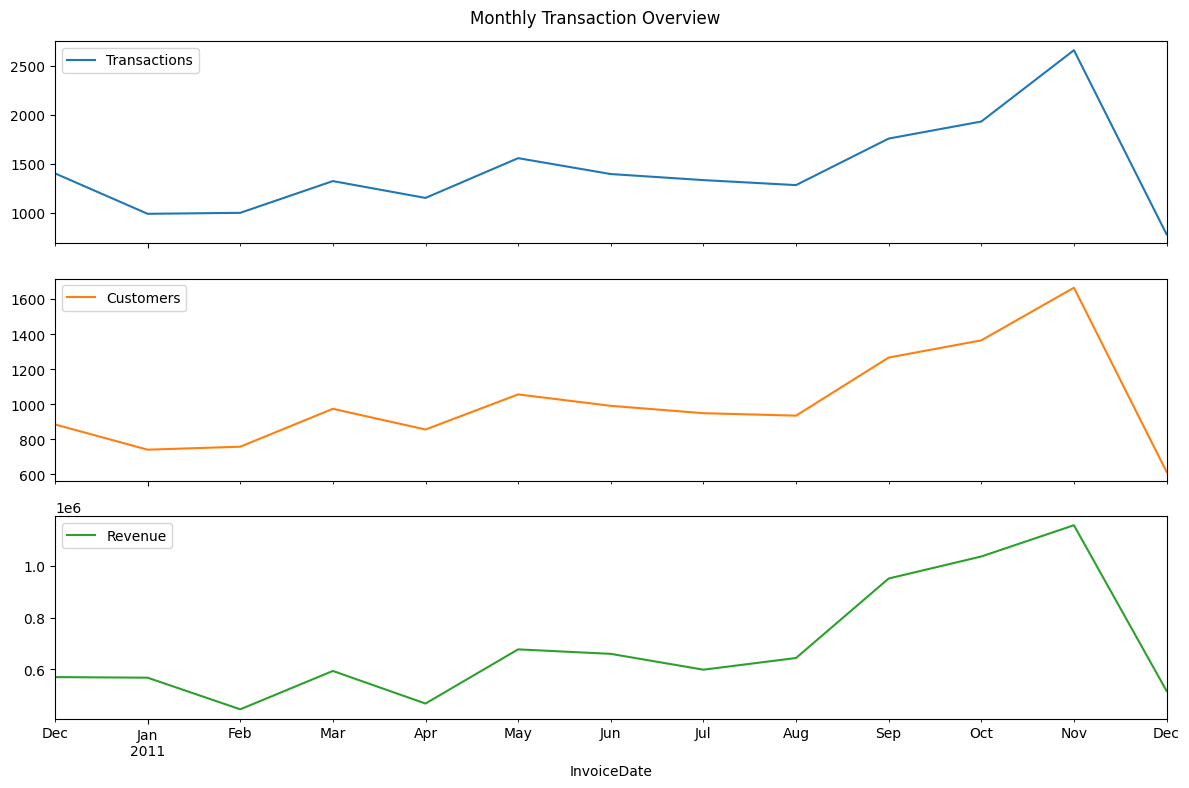

In [6]:
monthly_tx = df.set_index("InvoiceDate").resample("MS").agg(
    Transactions=("Invoice", "nunique"),
    Customers=("CustomerID", "nunique"),
    Revenue=("TotalAmount", "sum")
)
display(monthly_tx)
monthly_tx[["Transactions", "Customers", "Revenue"]].plot(
    subplots=True, figsize=(12, 8), title="Monthly Transaction Overview"
)
plt.tight_layout()
plt.show()


## 6. Temporal split & target definition

Each snapshot at month-end uses transactions up to that cutoff. The target is whether a previously known customer purchases during the **following calendar month**.

- Train snapshots: 2010-01 to 2010-12
- Validation snapshots: 2011-01 to 2011-06
- Test snapshots: 2011-07 to 2011-10

The October 2011 snapshot predicts November 2011, avoiding the incomplete December period in this dataset.


In [7]:
def month_periods(start=SNAPSHOT_START, end=SNAPSHOT_END):
    return pd.period_range(start=start, end=end, freq="M")

snapshot_periods = month_periods()
print(snapshot_periods)


PeriodIndex(['2010-01', '2010-02', '2010-03', '2010-04', '2010-05', '2010-06',
             '2010-07', '2010-08', '2010-09', '2010-10', '2010-11', '2010-12',
             '2011-01', '2011-02', '2011-03', '2011-04', '2011-05', '2011-06',
             '2011-07', '2011-08', '2011-09', '2011-10'],
            dtype='period[M]')


## 7. Snapshot generator: RFM + next-month purchase label

In [10]:
import pandas as pd
import numpy as np

# ============================================================
# 1. SNAPSHOT GENERATION
# ============================================================

def make_snapshot(data, period, window_days=None):

    period = pd.Period(period, freq="M")

    # Snapshot cutoff: beginning of next month
    cutoff = (period + 1).start_time

    # Future prediction period: next month
    next_period = period + 1

    next_start = next_period.start_time
    next_end = (next_period + 1).start_time

    # ========================================================
    # 2. HISTORICAL DATA
    # ========================================================

    hist = data[
        data["InvoiceDate"] < cutoff
    ].copy()

    # ========================================================
    # 3. FUTURE DATA (TARGET)
    # ========================================================

    future = data[
        (data["InvoiceDate"] >= next_start) &
        (data["InvoiceDate"] < next_end)
    ].copy()

    # ========================================================
    # 4. VALIDATE HISTORICAL DATA
    # ========================================================

    if hist.empty:

        print(f"Warning: No historical data before {period}")

        return pd.DataFrame(columns=[
            "CustomerID",
            "R",
            "F",
            "M",
            "Q",
            "snapshot",
            "snapshot_period",
            "window",
            "target_purchase_next_month"
        ])

    # Customers known before snapshot
    customers = hist["CustomerID"].unique()

    # ========================================================
    # 5. RECENCY
    # ========================================================

    last_purchase = (
        hist.groupby("CustomerID")["InvoiceDate"]
        .max()
    )

    recency = (
        (cutoff - last_purchase)
        .dt.days
        .rename("R")
    )

    # ========================================================
    # 6. SELECT RFM WINDOW
    # ========================================================

    if window_days is None:

        selected = hist.copy()
        suffix = "lifetime"

    else:

        start_date = cutoff - pd.Timedelta(
            days=window_days
        )

        selected = hist[
            hist["InvoiceDate"] >= start_date
        ].copy()

        suffix = f"{window_days}d"

    # ========================================================
    # 7. FREQUENCY / MONETARY / QUANTITY
    # ========================================================

    agg = (
        selected.groupby("CustomerID")
        .agg(
            F=("Invoice", "nunique"),
            M=("TotalAmount", "sum"),
            Q=("Quantity", "sum")
        )
    )

    # ========================================================
    # 8. BUILD SNAPSHOT
    # ========================================================

    out = pd.DataFrame(
        index=pd.Index(
            customers,
            name="CustomerID"
        )
    )

    out = out.join(recency)
    out = out.join(agg)

    out[["F", "M", "Q"]] = (
        out[["F", "M", "Q"]]
        .fillna(0)
    )

    out["snapshot"] = period.to_timestamp("M")

    out["snapshot_period"] = str(period)

    out["window"] = suffix

    # ========================================================
    # 9. FUTURE PURCHASE TARGET
    # ========================================================

    future_customers = set(
        future["CustomerID"].unique()
    )

    out["target_purchase_next_month"] = (
        out.index
        .isin(future_customers)
        .astype(int)
    )

    # ========================================================
    # 10. FINALIZE
    # ========================================================

    out = out.reset_index()

    return out


# ============================================================
# 11. SANITY CHECK
# ============================================================

print("Dataset date range:")
print(df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

# Use a valid snapshot period
sample = make_snapshot(
    data=df,
    period="2011-06",
    window_days=90
)

display(sample.head())

print("=" * 50)
print("SNAPSHOT REPORT")
print("=" * 50)

print("Snapshot period:", "2011-06")
print("Window:", "90 days")
print("Snapshot rows:", len(sample))

if not sample.empty:

    print(
        "Positive target rate:",
        sample["target_purchase_next_month"].mean()
    )

    print(
        "Customers purchasing next month:",
        sample["target_purchase_next_month"].sum()
    )

    print(
        "Customers not purchasing next month:",
        (sample["target_purchase_next_month"] == 0).sum()
    )

else:

    print("Snapshot is empty. Check dataset date range.")

Dataset date range:
2010-12-01 08:26:00 to 2011-12-09 12:50:00


,CustomerID,R,F,M,Q,snapshot,snapshot_period,window,target_purchase_next_month
0,17850,210,0.0,0.00,0.0,2011-06-30,2011-06,90d,0
1,13047,11,2.0,981.40,350.0,2011-06-30,2011-06,90d,0
2,12583,9,3.0,1039.44,1373.0,2011-06-30,2011-06,90d,1
3,13748,70,2.0,376.85,143.0,2011-06-30,2011-06,90d,0
4,15100,171,0.0,0.00,0.0,2011-06-30,2011-06,90d,0


SNAPSHOT REPORT
Snapshot period: 2011-06
Window: 90 days
Snapshot rows: 2960
Positive target rate: 0.2570945945945946
Customers purchasing next month: 761
Customers not purchasing next month: 2199


## 8. Build datasets for all candidate windows

In [11]:
snapshot_cache = {}
for window in WINDOWS:
    parts = [make_snapshot(df, p, window) for p in snapshot_periods]
    data_window = pd.concat(parts, ignore_index=True)
    snapshot_cache[window] = data_window
    print(window, "days:", data_window.shape, "positive rate:", round(data_window["target_purchase_next_month"].mean(), 4))

# Lifetime/static RFM baseline
static_parts = [make_snapshot(df, p, None) for p in snapshot_periods]
static_data = pd.concat(static_parts, ignore_index=True)


30 days: (28170, 9) positive rate: 0.289
60 days: (28170, 9) positive rate: 0.289
90 days: (28170, 9) positive rate: 0.289
120 days: (28170, 9) positive rate: 0.289
180 days: (28170, 9) positive rate: 0.289


## 9. Temporal feature engineering
Lag features are calculated only from earlier snapshots for the same customer.

In [12]:
BASE_FEATURES = ["R", "F", "M", "Q"]

def add_temporal_features(data):
    x = data.sort_values(["CustomerID", "snapshot"]).copy()
    for col in BASE_FEATURES:
        x[f"{col}_lag1"] = x.groupby("CustomerID")[col].shift(1)
        x[f"{col}_lag2"] = x.groupby("CustomerID")[col].shift(2)
        x[f"{col}_delta1"] = x[col] - x[f"{col}_lag1"]
    x["F_trend_3"] = x.groupby("CustomerID")["F"].transform(
        lambda s: s - s.shift(2)
    )
    x["M_trend_3"] = x.groupby("CustomerID")["M"].transform(
        lambda s: s - s.shift(2)
    )
    # Missing historical snapshots mean "no previous snapshot"; imputation happens in model pipeline.
    return x

feature_cache = {w: add_temporal_features(data) for w, data in snapshot_cache.items()}
static_features = add_temporal_features(static_data)
display(feature_cache[90].head())


,CustomerID,R,F,M,Q,snapshot,snapshot_period,window,target_purchase_next_month,R_lag1,R_lag2,R_delta1,F_lag1,F_lag2,F_delta1,M_lag1,M_lag2,M_delta1,Q_lag1,Q_lag2,Q_delta1,F_trend_3,M_trend_3
1989,12346,13,1.0,77183.6,74215.0,2011-01-31,2011-01,90d,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3291,12346,41,1.0,77183.6,74215.0,2011-02-28,2011-02,90d,0,13,NaN,28,1.0,NaN,0.0,77183.6,NaN,0.0,74215.0,NaN,0.0,NaN,NaN
4973,12346,72,1.0,77183.6,74215.0,2011-03-31,2011-03,90d,0,41,13,31,1.0,1.0,0.0,77183.6,77183.6,0.0,74215.0,74215.0,0.0,0.0,0.0
7107,12346,102,0.0,0.0,0.0,2011-04-30,2011-04,90d,0,72,41,30,1.0,1.0,-1.0,77183.6,77183.6,-77183.6,74215.0,74215.0,-74215.0,-1.0,-77183.6
9541,12346,133,0.0,0.0,0.0,2011-05-31,2011-05,90d,0,102,72,31,0.0,1.0,0.0,0.0,77183.6,0.0,0.0,74215.0,0.0,-1.0,-77183.6


## 10. Define temporal Train / Validation / Test

In [13]:
def split_temporal(data):
    p = data["snapshot_period"]
    train = data[p <= TRAIN_END].copy()
    valid = data[(p >= VALID_START) & (p <= VALID_END)].copy()
    test = data[(p >= TEST_START) & (p <= TEST_END)].copy()
    return train, valid, test

for w, data in feature_cache.items():
    tr, va, te = split_temporal(data)
    print(f"{w}d -> train={tr.shape}, validation={va.shape}, test={te.shape}")

train_static, valid_static, test_static = split_temporal(static_features)


30d -> train=(885, 23), validation=(13230, 23), test=(14055, 23)
60d -> train=(885, 23), validation=(13230, 23), test=(14055, 23)
90d -> train=(885, 23), validation=(13230, 23), test=(14055, 23)
120d -> train=(885, 23), validation=(13230, 23), test=(14055, 23)
180d -> train=(885, 23), validation=(13230, 23), test=(14055, 23)


## 11. Feature columns & evaluation functions

In [14]:
FEATURES = (
    BASE_FEATURES +
    [f"{c}_lag1" for c in BASE_FEATURES] +
    [f"{c}_lag2" for c in BASE_FEATURES] +
    [f"{c}_delta1" for c in BASE_FEATURES] +
    ["F_trend_3", "M_trend_3"]
)
TARGET = "target_purchase_next_month"

def get_xy(data):
    X = data[FEATURES].replace([np.inf, -np.inf], np.nan)
    y = data[TARGET].astype(int)
    return X, y

def make_lr():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))
    ])

def make_rf():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=250, max_depth=None, min_samples_leaf=2,
            class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
        ))
    ])

def metrics(y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    result = {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, prob) if len(np.unique(y_true)) > 1 else np.nan,
        "PR_AUC": average_precision_score(y_true, prob) if len(np.unique(y_true)) > 1 else np.nan
    }
    return result


## 12. Baseline comparison: Static RFM & Fixed Rolling Windows
Use Random Forest consistently for this first comparison. Window selection is based on Validation F1; Test remains untouched.

In [15]:
baseline_results = []
models_by_window = {}

# Static / lifetime baseline
for name, data in [("Static/Lifetime RFM", static_features)] + [
    (f"Fixed Rolling {w}d", feature_cache[w]) for w in WINDOWS
]:
    tr, va, te = split_temporal(data)
    Xtr, ytr = get_xy(tr)
    Xva, yva = get_xy(va)
    model = make_rf()
    model.fit(Xtr, ytr)
    pva = model.predict_proba(Xva)[:, 1]
    score = metrics(yva, pva)
    baseline_results.append({"Method": name, **score})
    models_by_window[name] = model

baseline_validation = pd.DataFrame(baseline_results).sort_values("F1", ascending=False)
display(baseline_validation)


,Method,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
4,Fixed Rolling 120d,0.691761,0.454763,0.457196,0.455977,0.683520,0.495786
5,Fixed Rolling 180d,0.673318,0.429672,0.477261,0.452218,0.681702,0.488452
0,Static/Lifetime RFM,0.670219,0.425648,0.478598,0.450573,0.679009,0.486701
3,Fixed Rolling 90d,0.701738,0.468806,0.418138,0.442025,0.676385,0.494617
2,Fixed Rolling 60d,0.714361,0.492112,0.342162,0.403661,0.655133,0.476924
1,Fixed Rolling 30d,0.718594,0.504720,0.214553,0.301108,0.585852,0.400813


## 13. Adaptive Rolling Window Selection
Choose the window with the highest Validation F1. This selection does not use Test labels.

In [16]:
adaptive_scores = baseline_validation[
    baseline_validation["Method"].str.startswith("Fixed Rolling")
].copy()

best_method = adaptive_scores.iloc[0]["Method"]
best_window = int(best_method.split()[-1].replace("d", ""))
print("Selected adaptive window:", best_window, "days")
print("Validation F1:", adaptive_scores.iloc[0]["F1"])


Selected adaptive window: 120 days
Validation F1: 0.45597652081109924


## 14. Proposed method: Adaptive RFM + Temporal Features
Train the selected window's model using Train and evaluate on Validation.

In [17]:
best_data = feature_cache[best_window]
train_best, valid_best, test_best = split_temporal(best_data)

X_train, y_train = get_xy(train_best)
X_valid, y_valid = get_xy(valid_best)
X_test, y_test = get_xy(test_best)

adaptive_rf = make_rf()
adaptive_rf.fit(X_train, y_train)
valid_prob = adaptive_rf.predict_proba(X_valid)[:, 1]
print("Adaptive Validation:", metrics(y_valid, valid_prob))


Adaptive Validation: {'Accuracy': 0.6917611489040061, 'Precision': 0.4547631718999468, 'Recall': 0.45719636169074374, 'F1': 0.45597652081109924, 'ROC_AUC': np.float64(0.6835196973622235), 'PR_AUC': np.float64(0.49578572762399464)}


## 15. Model comparison on Validation
Compare Logistic Regression, Random Forest and XGBoost when installed.

In [18]:
candidate_models = {
    "Logistic Regression": make_lr(),
    "Random Forest": make_rf()
}
try:
    from xgboost import XGBClassifier
    candidate_models["XGBoost"] = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", XGBClassifier(
            n_estimators=300, max_depth=5, learning_rate=0.05,
            subsample=0.8, colsample_bytree=0.8,
            eval_metric="logloss", random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])
except Exception as e:
    print("XGBoost unavailable; skipped:", e)

model_validation_rows = []
fitted_models = {}
for name, model in candidate_models.items():
    model.fit(X_train, y_train)
    p = model.predict_proba(X_valid)[:, 1]
    model_validation_rows.append({"Model": name, **metrics(y_valid, p)})
    fitted_models[name] = model

model_validation = pd.DataFrame(model_validation_rows).sort_values("F1", ascending=False)
display(model_validation)
best_model_name = model_validation.iloc[0]["Model"]
best_model = fitted_models[best_model_name]
print("Best validation model:", best_model_name)


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
1,Random Forest,0.691761,0.454763,0.457196,0.455977,0.683520,0.495786
0,Logistic Regression,0.667196,0.423475,0.492242,0.455277,0.678039,0.515984
2,XGBoost,0.695767,0.459452,0.434992,0.446887,0.677674,0.482005


Best validation model: Random Forest


## 16. Final Test evaluation
The Test set is evaluated only after window/model selection is completed.

In [19]:
test_prob = best_model.predict_proba(X_test)[:, 1]
test_result = metrics(y_test, test_prob)
print("Final Test Metrics")
display(pd.DataFrame([test_result], index=[best_model_name]))

test_pred = (test_prob >= 0.5).astype(int)
print(classification_report(y_test, test_pred, zero_division=0))
print("Confusion matrix:")
display(pd.DataFrame(
    confusion_matrix(y_test, test_pred),
    index=["Actual No Purchase", "Actual Purchase"],
    columns=["Predicted No Purchase", "Predicted Purchase"]
))


Final Test Metrics


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Random Forest,0.700818,0.481536,0.39951,0.436705,0.68465,0.493893


              precision    recall  f1-score   support

           0       0.77      0.82      0.80      9975
           1       0.48      0.40      0.44      4080

    accuracy                           0.70     14055
   macro avg       0.63      0.61      0.62     14055
weighted avg       0.69      0.70      0.69     14055

Confusion matrix:


,Predicted No Purchase,Predicted Purchase
Actual No Purchase,8220,1755
Actual Purchase,2450,1630


## 17. Baseline vs Proposed on Test
For a fair comparison, evaluate fixed 90-day RFM and the validation-selected adaptive window on the same Test period.

In [20]:
test_comparison_rows = []

# Static baseline
for name, data in [("Static/Lifetime RFM", static_features),
                    ("Fixed Rolling 90d", feature_cache[90]),
                    (f"Adaptive Rolling {best_window}d", feature_cache[best_window])]:
    tr, va, te = split_temporal(data)
    Xt, yt = get_xy(tr)
    Xte, yte = get_xy(te)
    model = make_rf()
    model.fit(Xt, yt)
    p = model.predict_proba(Xte)[:, 1]
    test_comparison_rows.append({"Method": name, **metrics(yte, p)})

# Proposed method uses selected window + temporal features (same feature construction)
tr, va, te = split_temporal(feature_cache[best_window])
Xt, yt = get_xy(tr)
Xte, yte = get_xy(te)
proposed_rf = make_rf()
proposed_rf.fit(Xt, yt)
p = proposed_rf.predict_proba(Xte)[:, 1]
test_comparison_rows.append({"Method": "Proposed Adaptive RFM + Temporal Features", **metrics(yte, p)})

test_comparison = pd.DataFrame(test_comparison_rows)
display(test_comparison.sort_values("F1", ascending=False))


,Method,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
3,Proposed Adaptive RFM + Temporal Features,0.700818,0.481536,0.399510,0.436705,0.684650,0.493893
2,Adaptive Rolling 120d,0.700818,0.481536,0.399510,0.436705,0.684650,0.493893
0,Static/Lifetime RFM,0.647670,0.406558,0.464951,0.433798,0.666365,0.470728
1,Fixed Rolling 90d,0.713625,0.509421,0.364461,0.424918,0.678828,0.496538


## 18. Visualize Test comparison

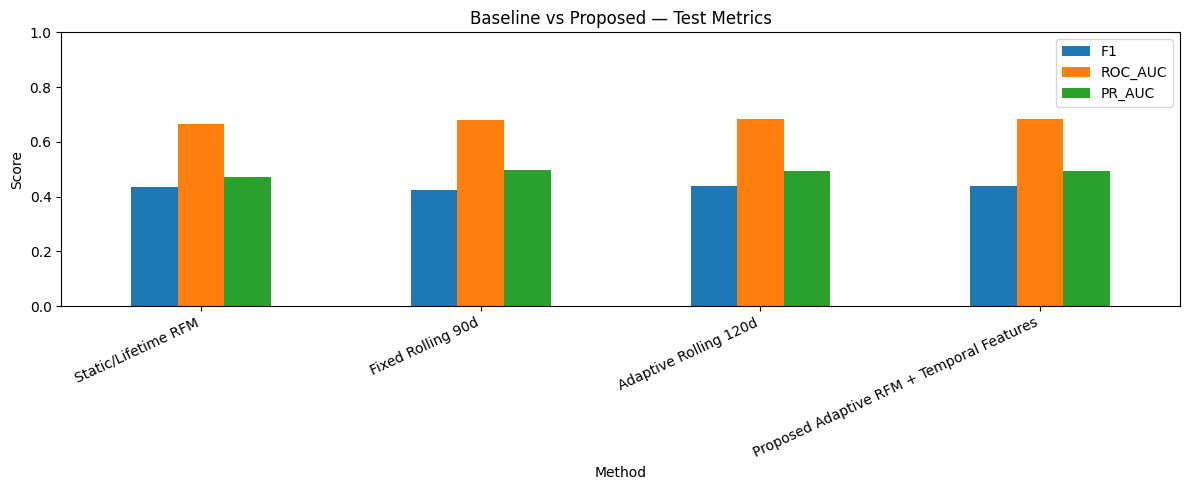

In [21]:
plot_df = test_comparison.set_index("Method")[["F1", "ROC_AUC", "PR_AUC"]]
plot_df.plot(kind="bar", figsize=(12, 5))
plt.title("Baseline vs Proposed — Test Metrics")
plt.ylabel("Score")
plt.xticks(rotation=25, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


## 19. Customer behavior analysis example

In [22]:
# Inspect the latest available test snapshot and customer predictions.
latest_test_snapshot = test_best["snapshot"].max()
latest = test_best[test_best["snapshot"] == latest_test_snapshot].copy()
latest_X = latest[FEATURES].replace([np.inf, -np.inf], np.nan)
latest["purchase_probability"] = best_model.predict_proba(latest_X)[:, 1]
latest["predicted_purchase"] = (latest["purchase_probability"] >= 0.5).astype(int)

display(latest.sort_values("purchase_probability", ascending=False).head(20))


,CustomerID,R,F,M,Q,snapshot,snapshot_period,window,target_purchase_next_month,R_lag1,R_lag2,R_delta1,F_lag1,F_lag2,F_delta1,M_lag1,M_lag2,M_delta1,Q_lag1,Q_lag2,Q_delta1,F_trend_3,M_trend_3,purchase_probability,predicted_purchase
24841,12540,13,8.0,5435.74,3038.0,2011-10-31,2011-10,120d,1,7,7,6,7.0,6.0,1.0,4351.46,5328.94,1084.28,2260.0,2710.0,778.0,2.0,106.80,0.971723,1
25500,13881,14,7.0,7194.01,3655.0,2011-10-31,2011-10,120d,1,1,7,13,8.0,6.0,-1.0,6154.72,4960.02,1039.29,3500.0,3232.0,155.0,1.0,2233.99,0.971448,1
24268,12921,7,15.0,6652.73,3668.0,2011-10-31,2011-10,120d,1,14,30,-7,14.0,13.0,1.0,5881.54,4687.30,771.19,3238.0,2725.0,430.0,2.0,1965.43,0.961026,1
25410,16133,0,16.0,6188.15,3621.0,2011-10-31,2011-10,120d,1,0,1,0,14.0,16.0,2.0,5591.62,5640.54,596.53,3221.0,3373.0,400.0,0.0,547.61,0.961026,1
24596,17675,0,11.0,7105.07,2962.0,2011-10-31,2011-10,120d,1,0,1,0,13.0,13.0,-2.0,7619.02,7759.34,-513.95,3097.0,3127.0,-135.0,-2.0,-654.27,0.960555,1
24500,17677,4,12.0,7260.77,4230.0,2011-10-31,2011-10,120d,1,12,0,-8,11.0,11.0,1.0,6458.10,7236.70,802.67,3902.0,4317.0,328.0,1.0,24.07,0.960521,1
24736,15856,6,12.0,5532.22,4510.0,2011-10-31,2011-10,120d,0,25,0,-19,9.0,8.0,3.0,4431.73,3772.58,1100.49,3524.0,3338.0,986.0,4.0,1759.64,0.958777,1
24214,13408,5,21.0,9619.21,5451.0,2011-10-31,2011-10,120d,1,5,6,0,20.0,21.0,1.0,8876.67,8180.49,742.54,5114.0,4518.0,337.0,0.0,1438.72,0.958553,1
25200,15189,4,15.0,6709.94,2658.0,2011-10-31,2011-10,120d,1,21,6,-17,18.0,15.0,-3.0,7714.32,7513.79,-1004.38,2940.0,2786.0,-282.0,0.0,-803.85,0.955737,1
24350,15061,10,12.0,12629.32,7680.0,2011-10-31,2011-10,120d,1,3,27,7,12.0,11.0,0.0,9844.84,9500.44,2784.48,5235.0,4984.0,2445.0,1.0,3128.88,0.955055,1


## 20. Research interpretation checklist

Khi báo cáo kết quả, cần trả lời:
1. Adaptive window có cải thiện F1/PR-AUC trên Validation và Test so với Fixed Rolling RFM không?
2. Temporal features có giúp dự báo tốt hơn RFM tại snapshot hiện tại không?
3. Model nào phù hợp nhất với dữ liệu?
4. Tỷ lệ positive/negative có mất cân bằng không? Nếu có, F1/PR-AUC quan trọng hơn Accuracy.
5. Có kiểm tra leakage không? Snapshot chỉ sử dụng dữ liệu trước cutoff; target lấy từ tháng kế tiếp.
6. Không tuyên bố cải tiến nếu Test metrics không hỗ trợ.

**Giới hạn:** Notebook hiện dự báo hành vi *có mua trong tháng tiếp theo hay không*. Đây là một mục tiêu cụ thể, kiểm chứng được và phù hợp với tên đề tài. Các mục tiêu như CLV, churn dài hạn hoặc segment-transition prediction có thể là nghiên cứu mở rộng, không nên gộp tất cả vào phiên bản đầu.
